In [675]:
import numpy as np
%matplotlib inline
import matplotlib.pyplot as plt


class Neural_Network(object):
    def __init__(self):
        #Define Parameters
        self.inputLayerSize = 2
        self.outputLayerSize=1
        self.hiddenLayerSize=3
        
        #Define Weights
        self.W1=np.random.rand(self.inputLayerSize,self.hiddenLayerSize)
        self.W2=np.random.rand(self.hiddenLayerSize,self.outputLayerSize)

    def forward(self,X):
        #Propagate inputs through network
        self.z2 = np.dot(X,self.W1)
        self.a2 = self.sigmoid(self.z2)
        self.z3 = np.dot(self.a2,self.W2)
        yHat = self.sigmoid(self.z3)
        return yHat
    
    def sigmoid(self, z):
        #Apply Sigmoid Activation Function
        return 1/(1+np.exp(-z))
    
    def sigmoidPrime(self,z):
        #Derivative of Sigmoid Function
        return np.exp(-z)/((1+np.exp(-z))**2)
    
    def relu(self, z):
        return np.maximum(0, z)
    
    def reluPrime(self,z):
        return 1 * (z > 0)

    def costFunctionPrimeRelu(self, X, y):
        self.yHat=self.forward(X)
        delta3 = np.multiply(-(y-self.yHat),self.reluPrime(self.z3))
        dJdW2=np.dot(self.a2.T,delta3)
        delta2=np.dot(delta3,self.W2.T)*self.reluPrime(self.z2)
        dJdW1=np.dot(X.T,delta2)
        return dJdW1,dJdW2

    def forwardRelu(self,X):
        self.z2 = np.dot(X,self.W1)
        self.a2 = self.relu(self.z2)
        self.z3 = np.dot(self.a2,self.W2)
        yHat = self.relu(self.z3)
        return yHat

    def costFunction(self, X, y):
        #Compute Cost Function with weights already stored in class
        self.yHat=self.forward(X)
        J=0.5*sum((y-self.yHat)**2)
        return J

    def costFunctionRelu(self, X,y):
        self.yHat=self.forwardRelu(X)
        J=0.5*sum((y-self.yHat)**2)
        return J
    
    def costFunctionPrime(self, X, y):
        #Compute derivatives with respect to W1 and W2
        self.yHat=self.forward(X)
        delta3 = np.multiply(-(y-self.yHat),self.sigmoidPrime(self.z3))
        dJdW2=np.dot(self.a2.T,delta3)
        delta2=np.dot(delta3,self.W2.T)*self.sigmoidPrime(self.z2)
        dJdW1=np.dot(X.T,delta2)
        return dJdW1,dJdW2


In [676]:
X=np.array(([3,5],[5,1],[10,1]),dtype=float)
y=np.array(([75],[80],[93]),dtype=float)

In [677]:
X


array([[ 3.,  5.],
       [ 5.,  1.],
       [10.,  1.]])

In [678]:
y

array([[75.],
       [80.],
       [93.]])

In [679]:
X=X/np.amax(X,axis=0)
y=y/100

In [680]:
X,y


(array([[0.3, 1. ],
        [0.5, 0.2],
        [1. , 0.2]]),
 array([[0.75],
        [0.8 ],
        [0.93]]))

In [681]:
NN=Neural_Network()

In [682]:
yH=NN.forward(X)

In [683]:
yH

array([[0.76319451],
       [0.7490865 ],
       [0.77211229]])

In [684]:
y

array([[0.75],
       [0.8 ],
       [0.93]])

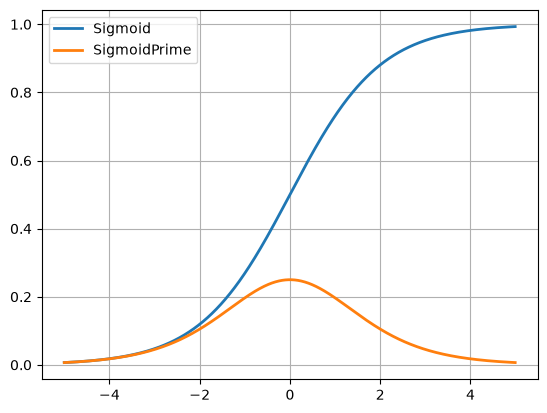

In [685]:
testValues=np.arange(-5,5,0.01)
plt.plot(testValues,NN.sigmoid(testValues),linewidth=2)
plt.plot(testValues, NN.sigmoidPrime(testValues),linewidth=2)
plt.grid(1)
plt.legend(['Sigmoid','SigmoidPrime'])


In [686]:
NN=Neural_Network()

In [687]:
cost1=NN.costFunction(X,y)

In [688]:
cost1

array([0.04161091])

In [689]:
dJdW1,dJdW2=NN.costFunctionPrime(X,y)

In [690]:
dJdW1

array([[-0.00929877, -0.00476689, -0.00577513],
       [-0.00470634, -0.00231552, -0.00301649]])

In [691]:
dJdW2

array([[-0.06185906],
       [-0.05600896],
       [-0.0664048 ]])

In [692]:
scalar= 3
NN.W1 = NN.W1+scalar*dJdW1
NN.W2 = NN.W2+scalar*dJdW2
cost2 = NN.costFunction(X,y)
print (cost1,cost2)

[0.04161091] [0.08697355]


In [693]:
scalar= 3 #this is our alpha
NN.W1 = NN.W1-scalar*dJdW1
NN.W2 = NN.W2-scalar*dJdW2
cost3 = NN.costFunction(X,y)
print (cost2,cost3)

[0.08697355] [0.04161091]


In [694]:
# NN.W1 = NN.W1 + scalar*(NN.yHat-NN.a3)*NN.sigmoidPrime(NN.z3)*array([NN.X[0,0], NN.X[0,1], NN.X[0,2]],[NN.X[1,0], NN.X[1,1], NN.X[1,2]])
# NN.W1

[[0.6559357  0.23357564 0.89783704]
 [0.03292279 0.20216219 0.11360739]] [[0.55933315]
 [0.26805355]
 [0.37458534]]


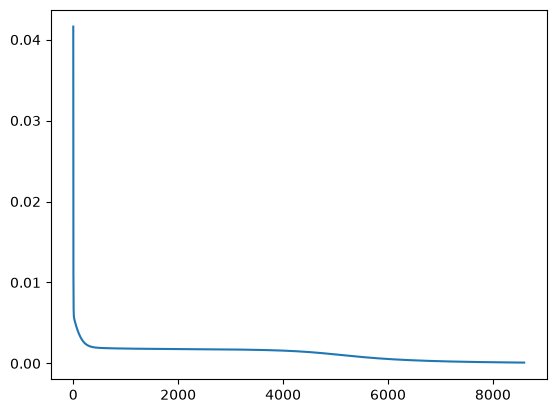

In [695]:
def minimize(alpha, accuracyPoop):
    W1_init = NN.W1
    W2_init = NN.W2
    print(W1_init,W2_init)
    cost = NN.costFunction(X, y)
    cost_arr = [cost]
    while cost_arr[-1] > accuracyPoop:

        dJdW1, dJdW2 = NN.costFunctionPrime(X, y)

        NN.W1 = NN.W1-alpha*dJdW1
        NN.W2 = NN.W2-alpha*dJdW2

        cost = NN.costFunction(X, y)
        cost_arr.append(cost)

    return cost_arr

cost_arr = (minimize(2, .0001))

# print(cost_arr)
plt.plot(cost_arr)

In [ ]:
y

In [ ]:
NN.forward(X)

In [698]:

class ReluNeural_Network(object):
    def __init__(self):
        #Define Parameters
        self.inputLayerSize = 2
        self.outputLayerSize=1
        self.hiddenLayerSize=3

        #Define Weights
        self.W1=np.random.rand(self.inputLayerSize,self.hiddenLayerSize)
        self.W2=np.random.rand(self.hiddenLayerSize,self.outputLayerSize)

    def forward(self,X):
        #Propagate inputs through network
        self.z2 = np.dot(X,self.W1)
        self.a2 = self.relu(self.z2)
        self.z3 = np.dot(self.a2,self.W2)
        yHat = self.sigmoid(self.z3)
        return yHat

    def relu(self, z):
        return np.maximum(0, z)

    def reluPrime(self,z):
        return 1 * (z > 0)

    def sigmoid(self, z):
        #Apply Sigmoid Activation Function
        return 1/(1+np.exp(-z))

    def costFunction(self, X, y):
        #Compute Cost Function with weights already stored in class
        self.yHat=self.forward(X)
        J=0.5*sum((y-self.yHat)**2)
        return J


    def costFunctionPrime(self, X, y):
        #Compute derivatives with respect to W1 and W2
        self.yHat=self.forward(X)
        delta3 = np.multiply(-(y-self.yHat),self.reluPrime(self.z3))
        dJdW2=np.dot(self.a2.T,delta3)
        delta2=np.dot(delta3,self.W2.T)*self.reluPrime(self.z2)
        dJdW1=np.dot(X.T,delta2)
        return dJdW1,dJdW2


[[0.05177234 0.48575476 0.57218408]
 [0.51848649 0.56932274 0.40310498]] [[0.45875149]
 [0.86077499]
 [0.22049585]]


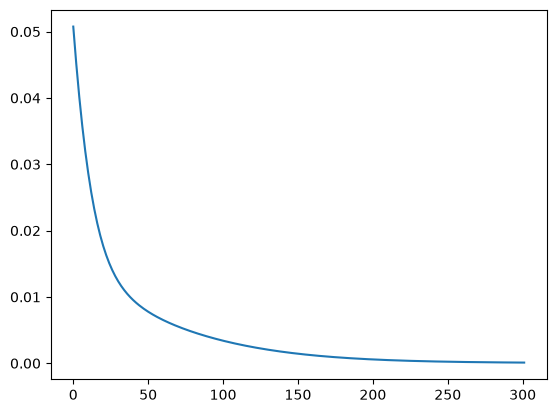

In [699]:
ReluNN = ReluNeural_Network()

def minimizeRelu(alpha, accuracyPoop):
    W1_init = ReluNN.W1
    W2_init = ReluNN.W2
    print(W1_init,W2_init)
    cost = ReluNN.costFunction(X, y)
    cost_arr = [cost]
    while cost_arr[-1] > accuracyPoop:

        dJdW1, dJdW2 = ReluNN.costFunctionPrime(X, y)

        ReluNN.W1 = ReluNN.W1-alpha*dJdW1
        ReluNN.W2 = ReluNN.W2-alpha*dJdW2

        cost = ReluNN.costFunction(X, y)
        cost_arr.append(cost)

    return cost_arr

cost_arrRelu = (minimizeRelu(.05, .0001))

# print(cost_arr)
plt.plot(cost_arrRelu)

In [700]:
ReluNN.forward(X)-y

array([[ 0.00921402],
       [-0.01058866],
       [-0.0016274 ]])

In [ ]:
Relu_